In [59]:
import os
import json
import glob
import shutil
from datetime import datetime
import pandas as pd
import numpy as np
from pathlib import Path
from tqdm import tqdm
import matplotlib.pyplot as plt
import pyarrow as pa
import pyarrow.parquet as pq
import torch
import torch.nn as nn 


In [60]:
def set_all_seeds(seed=42):
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_all_seeds(42)

In [61]:
class Config:
    # Paths
    DATA_DIR = Path("../data")
    FINAL_DATA_DIR = DATA_DIR / "final_data"
    ARTIFACT_DIR = DATA_DIR / "artifacts"
    CF_DIR = ARTIFACT_DIR / "cf"
    PARQUET_DIR = DATA_DIR / "interactions_parquet"
    
    RATINGS_PATH = FINAL_DATA_DIR / "ratings_filtered_by_movie.csv" 
    
    
    # Data Schema
    USER_COL = "userId"
    MOVIE_COL = "movieId"
    RATING_COL = "rating"
    TIMESTAMP_COL = "timestamp"
    
    # Lọc và Chia tập (Top N mới nhất)
    MAX_ROWS_TO_PROCESS = 1_000_000
    TRAIN_RATIO = 0.8
    VAL_RATIO = 0.1
    TEST_RATIO = 0.1
    
    # Hyperparameters
    EMBEDDING_DIM = 64
    INIT_STD = 0.01
    BATCH_SIZE = 1024 
    CHUNK_SIZE = 500000 
    EPOCHS = 10
    LEARNING_RATE = 0.002
    WEIGHT_DECAY = 1e-4
    DROPOUT_RATE = 0.2
    
    DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
    
    # Tiền tố Versioning bằng Timestamp
    RUN_TIMESTAMP = f"{datetime.now().strftime('%Y%m%d_%H%M%S')}_{1_000_000}"
    # RUN_TIMESTAMP = '20261019_124842_1000000'
    
    TOP_K = 10  # Số lượng đề xuất hàng đầu cho mỗi người dùng
    RELEVANCE_THRESHOLD = 4.0  # Rating >= ngưỡng này được xem là phim relevant
    RANDOM_STATE = 42
    
    @classmethod
    def setup(cls):
        cls.PARQUET_DIR.mkdir(parents=True, exist_ok=True)
        cls.CF_DIR.mkdir(parents=True, exist_ok=True)
        os.makedirs(cls.ARTIFACT_DIR, exist_ok=True)
        (cls.PARQUET_DIR / "train").mkdir(exist_ok=True)
        (cls.PARQUET_DIR / "val").mkdir(exist_ok=True)
        (cls.PARQUET_DIR / "test").mkdir(exist_ok=True)
        print(f"[INFO] Target Device: {cls.DEVICE}")
        print(f"[INFO] Training Run ID: {cls.RUN_TIMESTAMP}")

Config.setup()


[INFO] Target Device: cpu
[INFO] Training Run ID: 20261019_191617_1000000


In [62]:
import pandas as pd
import numpy as np
from pathlib import Path

# ============================================================
# PAPER-STYLE PREPROCESSING (NCF - He et al. 2017)
# - Rating → binary 1 (implicit signal, như paper)
# - Filter user ≥ 20 interactions
# - Split LOO (Leave-One-Out)
# ============================================================

def preprocess_paper_style(
    csv_path,
    user_col='userId',
    movie_col='movieId',
    rating_col='rating',
    timestamp_col='timestamp',
    max_rows=1_000_000,
    min_interactions=20,
    chunk_size=200_000,
    verbose=True,
):
    """Pipeline chuẩn paper NCF."""
    
    # ---- BƯỚC 1: Chunked read, giữ top-N mới nhất ----
    if verbose: print(f"[1/5] Reading top {max_rows:,} newest interactions...")
    recent = pd.DataFrame()
    for chunk in pd.read_csv(
        csv_path,
        usecols=[user_col, movie_col, rating_col, timestamp_col],
        chunksize=chunk_size,
    ):
        recent = pd.concat([recent, chunk], ignore_index=True)
        recent = recent.nlargest(max_rows, timestamp_col)
    
    recent = recent.dropna(subset=[user_col, movie_col, rating_col, timestamp_col])
    if verbose: print(f"      Loaded {len(recent):,} rows, {recent[user_col].nunique():,} users, "
                      f"{recent[movie_col].nunique():,} items")
    
    # ---- BƯỚC 2: Stats trước filter ----
    user_counts = recent[user_col].value_counts()
    if verbose:
        print(f"[2/5] Before filter (per-user stats):")
        print(f"      min={user_counts.min()} | median={user_counts.median():.0f} | "
              f"max={user_counts.max()} | mean={user_counts.mean():.1f}")
        print(f"      Users with ≥{min_interactions}: {(user_counts >= min_interactions).sum():,} "
              f"({(user_counts >= min_interactions).mean()*100:.1f}%)")
    
    # ---- BƯỚC 3: Filter user ≥ min_interactions (paper) ----
    users_keep = user_counts[user_counts >= min_interactions].index
    df = recent[recent[user_col].isin(users_keep)].copy()
    if verbose: print(f"[3/5] After filter: {len(df):,} rows, {len(users_keep):,} users")
    
    # ---- BƯỚC 4: Binarize + Sort + Mapping ----
    # Paper: mọi rating đều thành 1 (chỉ cần "user đã tương tác")
    df['label'] = 1
    
    # Sort tie-break bằng movieId để đảm bảo deterministic
    df = df.sort_values(
        [user_col, timestamp_col, movie_col], kind='stable'
    ).reset_index(drop=True)
    
    user_mapping = {str(u): i for i, u in enumerate(df[user_col].unique())}
    movie_mapping = {str(m): i for i, m in enumerate(df[movie_col].unique())}
    df['user_idx'] = df[user_col].astype(str).map(user_mapping)
    df['movie_idx'] = df[movie_col].astype(str).map(movie_mapping)
    if verbose: print(f"[4/5] Mapping done: {len(user_mapping):,} users, {len(movie_mapping):,} items")
    
    # ---- BƯỚC 5: LOO split ----
    train_parts, val_parts, test_parts = [], [], []
    for uid, group in df.groupby('user_idx', sort=False):
        n = len(group)
        # Guaranteed n >= 20 by filter
        train_parts.append(group.iloc[:-2])
        val_parts.append(group.iloc[-2:-1])
        test_parts.append(group.iloc[-1:])
    
    train_df = pd.concat(train_parts, ignore_index=True)
    val_df = pd.concat(val_parts, ignore_index=True)
    test_df = pd.concat(test_parts, ignore_index=True)
    
    # ---- Report cuối ----
    if verbose:
        print(f"[5/5] Split summary:")
        print(f"      Train: {len(train_df):,} rows | {train_df['user_idx'].nunique():,} users")
        print(f"      Val:   {len(val_df):,} rows | {val_df['user_idx'].nunique():,} users")
        print(f"      Test:  {len(test_df):,} rows | {test_df['user_idx'].nunique():,} users")
        sparsity = 1 - len(df) / (len(user_mapping) * len(movie_mapping))
        print(f"      Sparsity: {sparsity:.4%}")
        print(f"      Coverage: 100% (all filtered users evaluated)")
    
    return train_df, val_df, test_df, user_mapping, movie_mapping


# ============================================================
# CHẠY
# ============================================================
train_df, val_df, test_df, user_mapping, movie_mapping = preprocess_paper_style(
    csv_path=Config.RATINGS_PATH,
    user_col=Config.USER_COL,
    movie_col=Config.MOVIE_COL,
    rating_col=Config.RATING_COL,
    timestamp_col=Config.TIMESTAMP_COL,
    max_rows=Config.MAX_ROWS_TO_PROCESS,     
    min_interactions=20,
)


# ---------- 2. ĐỌC MAPPING để lấy num_users / num_movies ----------
# A. Khởi tạo đường dẫn động (Version bằng Timestamp)
dir_path_with_timestamp: Path =  Config.CF_DIR / Config.RUN_TIMESTAMP
os.makedirs(dir_path_with_timestamp, exist_ok=True)

def get_timestamped_path(base_dir: Path, postfix_filename: str) -> Path:
    """
    Tạo đường dẫn tệp với tiền tố timestamp.
    
    Args:
        base_dir (Path): Thư mục cơ sở để lưu tệp.
        postfix_filename (str): Tên tệp gốc.
        
    Returns:
        Path: Đường dẫn tệp mới với tiền tố timestamp.
    """
    return base_dir / f"{Config.RUN_TIMESTAMP}_{postfix_filename}"

num_users  = len(user_mapping)
num_movies = len(movie_mapping)

# ---------- 3. BIẾN DÙNG CHUNG ----------
DEVICE       = torch.device(Config.DEVICE)
RATING_COL   = Config.RATING_COL
USER_COL_IDX = "user_idx"
MOVIE_COL_IDX = "movie_idx"
TOP_K        = Config.TOP_K
RUN_ID       = Config.RUN_TIMESTAMP

# ---------- 4. IN RA ĐỂ VERIFY ----------
print("=" * 60)
print(f"TRAIN: {len(train_df):>9,} rows | users={train_df['user_idx'].nunique():>6,}")
print(f"VAL:   {len(val_df):>9,} rows | users={val_df['user_idx'].nunique():>6,}")
print(f"TEST:  {len(test_df):>9,} rows | users={test_df['user_idx'].nunique():>6,}")
print(f"num_users={num_users:,} | num_movies={num_movies:,} | device={DEVICE}")
print(f"rating range: [{train_df[RATING_COL].min()}, {train_df[RATING_COL].max()}]")
print("=" * 60)

[1/5] Reading top 1,000,000 newest interactions...
      Loaded 1,000,000 rows, 62,683 users, 2,583 items
[2/5] Before filter (per-user stats):
      min=1 | median=7 | max=1554 | mean=16.0
      Users with ≥20: 13,140 (21.0%)
[3/5] After filter: 697,358 rows, 13,140 users
[4/5] Mapping done: 13,140 users, 2,557 items
[5/5] Split summary:
      Train: 671,078 rows | 13,140 users
      Val:   13,140 rows | 13,140 users
      Test:  13,140 rows | 13,140 users
      Sparsity: 97.9245%
      Coverage: 100% (all filtered users evaluated)
TRAIN:   671,078 rows | users=13,140
VAL:      13,140 rows | users=13,140
TEST:     13,140 rows | users=13,140
num_users=13,140 | num_movies=2,557 | device=cpu
rating range: [0.5, 5.0]


In [63]:
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from scipy.sparse import csr_matrix
from tqdm.auto import tqdm

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# ---------- Seen items map (dùng cho TẤT CẢ model) ----------
def build_seen_map(df: pd.DataFrame) -> dict:
    """user_idx -> set(movie_idx) đã tương tác."""
    return df.groupby("user_idx")["movie_idx"].apply(set).to_dict()

TRAIN_SEEN = build_seen_map(train_df)

# ---------- Metrics ----------
def _precision_recall(recs, rel, k):
    hits = len(set(recs[:k]) & rel)
    p = hits / k
    r = hits / len(rel) if rel else 0.0
    return p, r

def _f1(p, r):
    return 2*p*r/(p+r) if (p+r) else 0.0

def _hit_rate(recs, rel, k):
    return 1.0 if set(recs[:k]) & rel else 0.0

def _ndcg(recs, rel, k):
    dcg = sum(1/np.log2(r+2) for r, m in enumerate(recs[:k]) if m in rel)
    idcg = sum(1/np.log2(r+2) for r in range(min(len(rel), k)))
    return dcg/idcg if idcg else 0.0

def _mrr(recs, rel):
    for r, m in enumerate(recs):
        if m in rel: return 1.0/(r+1)
    return 0.0

def _map(recs, rel):
    if not rel: return 0.0
    hits, s = 0, 0.0
    for r, m in enumerate(recs):
        if m in rel:
            hits += 1
            s += hits/(r+1)
    return s/len(rel)

# ---------- Fair Evaluation: tất cả model đều filter seen ----------
def evaluate_recommender(model, eval_df: pd.DataFrame, train_df: pd.DataFrame,
                          k: int = 10, verbose: bool = True) -> dict:
    """
    Đánh giá công bằng: với mỗi user trong eval_df,
    gọi model.recommend(user_idx, seen_items, k) để lấy top-K,
    rồi tính metric so với relevant items trong eval_df.
    """
    seen_map = build_seen_map(train_df)
    rows = []
    for uid, grp in eval_df.groupby("user_idx"):
        uid = int(uid)
        rel = set(grp["movie_idx"].values)
        seen = seen_map.get(uid, set())
        recs = model.recommend(uid, seen, k)
        p, r = _precision_recall(recs, rel, k)
        rows.append({
            "precision@k": p, "recall@k": r, "f1@k": _f1(p, r),
            "hit_rate@k": _hit_rate(recs, rel, k),
            "ndcg@k": _ndcg(recs, rel, k),
            "mrr@k": _mrr(recs, rel),
            "map@k": _map(recs, rel),
        })
    result = {m: float(np.mean([row[m] for row in rows])) for m in rows[0]}
    result["k"] = k
    result["n_users"] = len(rows)
    if verbose:
        print(f"  Users={len(rows)} | P@{k}={result['precision@k']:.4f} "
              f"| R@{k}={result['recall@k']:.4f} | NDCG@{k}={result['ndcg@k']:.4f} "
              f"| HR@{k}={result['hit_rate@k']:.4f}")
    return result

# ============================================================
# HÀM ĐÁNH GIÁ CHUẨN PAPER NCF
# Protocol: 1 positive + 99 sampled negatives = 100 candidates
# Từ: github.com/hexiangnan/neural_collaborative_filtering (evaluate.py)
# ============================================================

def evaluate_recommender_100cands(
    model, eval_df, train_df, num_items,
    k=10, num_neg=99, seed=42, verbose=True,
):
    """
    Paper NCF protocol:
    - Với mỗi user, lấy 1 positive item từ test
    - Sample 99 negatives chưa tương tác trong train và không trùng positive
    - Score 100 candidates, rank positive
    - Đây là cách paper báo HR@10 ~0.71 trên MovieLens
    """
    seen_map = build_seen_map(train_df)
    rng = np.random.default_rng(seed)
    rows = []
    n_skipped = 0
    
    for uid, grp in eval_df.groupby("user_idx"):
        uid = int(uid)
        pos_item = int(grp["movie_idx"].iloc[0])
        seen = seen_map.get(uid, set())
        excluded = seen | {pos_item}
        
        # Sample 99 negatives
        negs = []
        attempts = 0
        max_attempts = num_neg * 20
        while len(negs) < num_neg and attempts < max_attempts:
            j = int(rng.integers(0, num_items))
            if j not in excluded and j not in negs:
                negs.append(j)
            attempts += 1
        
        if len(negs) < num_neg:
            n_skipped += 1
            continue
        
        # Score 100 candidates
        candidates = np.array([pos_item] + negs, dtype=np.int64)
        all_scores = model.predict_all(uid)
        cand_scores = all_scores[candidates]
        
        # Rank positive (nó ở vị trí 0 trong candidates)
        order = np.argsort(-cand_scores)
        rank = int(np.where(order == 0)[0][0]) + 1
        
        # Metrics (LOO — 1 relevant item)
        hit = 1.0 if rank <= k else 0.0
        rows.append({
            "precision@k": hit / k,
            "recall@k": hit,
            "hit_rate@k": hit,
            "ndcg@k": (1.0 / np.log2(rank + 1)) if rank <= k else 0.0,
            "mrr@k": (1.0 / rank) if rank <= k else 0.0,
        })
    
    result = {m: float(np.mean([r[m] for r in rows])) for m in rows[0]}
    result["k"] = k
    result["n_users"] = len(rows)
    result["n_skipped"] = n_skipped
    
    if verbose:
        print(f"  [100-cand] Users={len(rows)} (skip={n_skipped}) | "
              f"P@{k}={result['precision@k']:.4f} | "
              f"NDCG@{k}={result['ndcg@k']:.4f} | "
              f"HR@{k}={result['hit_rate@k']:.4f}")
    return result

 

print(f"[OK] Utilities loaded. Device={DEVICE}")

[OK] Utilities loaded. Device=cpu


In [67]:
class PopularityBaseline:
    """Gợi ý phim phổ biến nhất (count interactions trong train)."""
    name = "Popularity"

    def __init__(self, train_df: pd.DataFrame):
        counts = train_df.groupby("movie_idx").size()
        self.ranked = counts.sort_values(ascending=False).index.values
        self.num_movies = len(counts)

    def recommend(self, user_idx: int, seen_items: set, k: int = 10):
        recs = []
        for i in self.ranked:
            if int(i) not in seen_items:
                recs.append(int(i))
                if len(recs) >= k:
                    break
        return recs

# ---------- Test ----------
# pop_model = PopularityBaseline(train_df)
# print("\n[Popularity Baseline] Đánh giá trên TEST:")
# pop_test = evaluate_recommender(pop_model, test_df, train_df, k=10)


class PopularityBaseline:
    name = "Popularity"
    
    def __init__(self, train_df, num_movies):
        counts = train_df.groupby("movie_idx").size()
        self.ranked = counts.sort_values(ascending=False).index.values
        self.num_movies = num_movies     # ← dùng tổng từ mapping, KHÔNG phải len(counts)
    
    def predict_all(self, user_idx):
        """
        Movie không có trong train (cold item) → score = -1e9 (luôn xếp cuối).
        Movie có trong train → score = -rank (phổ biến hơn = score cao hơn).
        """
        scores = np.full(self.num_movies, -1e9, dtype=np.float32)
        for rank_pos, movie_id in enumerate(self.ranked):
            scores[int(movie_id)] = -rank_pos
        return scores
    
    def recommend(self, user_idx, seen_items, k=10):
        recs = []
        for i in self.ranked:
            if int(i) not in seen_items:
                recs.append(int(i))
                if len(recs) >= k:
                    break
        return recs


# ---------- Chạy lại ----------
set_all_seeds(42)
pop_model = PopularityBaseline(train_df, num_movies)   # ← truyền num_movies

print("[Popularity]")
pop_100  = evaluate_recommender_100cands(pop_model, test_df, train_df, num_movies, k=10)
pop_full = evaluate_recommender(pop_model, test_df, train_df, k=10, verbose=False)
print(f"  [Full rank] HR@10={pop_full['hit_rate@k']:.4f}")

[Popularity]
  [100-cand] Users=13140 (skip=0) | P@10=0.0780 | NDCG@10=0.4714 | HR@10=0.7797
  [Full rank] HR@10=0.1365


In [ ]:
class MF_SGD(nn.Module):
    """Biased Matrix Factorization + SGD (MSE loss)."""
    name = "MF-SGD (MSE)"

    def __init__(self, num_users, num_movies, dim=64, init_std=0.01, use_sigmoid=False):
        super().__init__()
        self.user_embedding  = nn.Embedding(num_users, dim)
        self.movie_embedding = nn.Embedding(num_movies, dim)
        self.user_bias  = nn.Embedding(num_users, 1)
        self.movie_bias = nn.Embedding(num_movies, 1)
        self.global_bias = nn.Parameter(torch.zeros(1))
        self.use_sigmoid = use_sigmoid
        self.min_rating, self.max_rating = 0.5, 5.0
        nn.init.normal_(self.user_embedding.weight,  std=init_std)
        nn.init.normal_(self.movie_embedding.weight, std=init_std)
        nn.init.zeros_(self.user_bias.weight)
        nn.init.zeros_(self.movie_bias.weight)

    def forward(self, u, m):
        ue = self.user_embedding(u)
        me = self.movie_embedding(m)
        raw = (ue * me).sum(-1) + self.user_bias(u).squeeze(-1) \
              + self.movie_bias(m).squeeze(-1) + self.global_bias
        if self.use_sigmoid:
            raw = (self.max_rating - self.min_rating) * torch.sigmoid(raw) + self.min_rating
        return raw

    @torch.no_grad()
    def predict_all(self, user_idx: int) -> np.ndarray:
        self.eval()
        num_m = self.movie_embedding.num_embeddings
        u = torch.tensor([user_idx]*num_m, dtype=torch.long, device=DEVICE)
        m = torch.arange(num_m, device=DEVICE)
        return self(u, m).cpu().numpy()

    def recommend(self, user_idx: int, seen_items: set, k: int = 10):
        scores = self.predict_all(user_idx)
        for i in seen_items:
            scores[i] = -np.inf
        return np.argsort(-scores)[:k].tolist()


def train_mf_sgd(model, train_df, val_df=None, epochs=10, batch_size=4096,
                 lr=2e-3, weight_decay=1e-5, rating_col="rating",
                 patience=3, ckpt_path="best_mf_sgd.pt"):
    """Train MF-SGD với val early stopping dựa trên Val RMSE."""
    model.to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    
    users   = torch.tensor(train_df["user_idx"].values, dtype=torch.long)
    movies  = torch.tensor(train_df["movie_idx"].values, dtype=torch.long)
    ratings = torch.tensor(train_df[rating_col].values, dtype=torch.float32)
    n = len(users)
    
    best_rmse, patience_count = float("inf"), 0
    
    for epoch in range(1, epochs+1):
        model.train()
        perm = torch.randperm(n)
        total_loss = 0.0
        for start in range(0, n, batch_size):
            idx = perm[start:start+batch_size]
            u, m, r = users[idx].to(DEVICE), movies[idx].to(DEVICE), ratings[idx].to(DEVICE)
            pred = model(u, m)
            loss = F.mse_loss(pred, r)
            opt.zero_grad(); loss.backward(); opt.step()
            total_loss += loss.item() * len(idx)
        train_mse = total_loss / n
        
        # Val
        if val_df is not None and len(val_df):
            model.eval()
            with torch.no_grad():
                vu = torch.tensor(val_df["user_idx"].values, dtype=torch.long, device=DEVICE)
                vm = torch.tensor(val_df["movie_idx"].values, dtype=torch.long, device=DEVICE)
                vr = torch.tensor(val_df[rating_col].values, dtype=torch.float32, device=DEVICE)
                val_mse = 0.0
                for s in range(0, len(vu), batch_size):
                    pred = model(vu[s:s+batch_size], vm[s:s+batch_size])
                    val_mse += F.mse_loss(pred, vr[s:s+batch_size], reduction="sum").item()
                val_mse /= len(vu)
            val_rmse = np.sqrt(val_mse)
            print(f"Epoch {epoch:2d} | TrainMSE={train_mse:.4f} | ValRMSE={val_rmse:.4f}")
            if val_rmse < best_rmse - 1e-4:
                best_rmse = val_rmse
                torch.save(model.state_dict(), ckpt_path)
                patience_count = 0
            else:
                patience_count += 1
                if patience_count >= patience:
                    print(f"  Early stop at epoch {epoch}. Best ValRMSE={best_rmse:.4f}")
                    break
        else:
            print(f"Epoch {epoch:2d} | TrainMSE={train_mse:.4f}")
    
    if val_df is not None and __import__("os").path.exists(ckpt_path):
        model.load_state_dict(torch.load(ckpt_path, map_location=DEVICE))
    return model


# ---------- Train & Test ----------
mf_sgd = MF_SGD(num_users, num_movies, dim=64, use_sigmoid=False)
checkpoint_path = get_timestamped_path(dir_path_with_timestamp, "best_mf_sgd.pt")
mf_sgd = train_mf_sgd(mf_sgd, train_df, val_df, epochs=15, batch_size=4096,
                      lr=2e-3, patience=3, ckpt_path=checkpoint_path)

print("\n[MF-SGD] Đánh giá trên TEST:")
mf_test = evaluate_recommender(mf_sgd, test_df, train_df, k=10)

Epoch  1 | TrainMSE=7.2070 | ValRMSE=1.2191
Epoch  2 | TrainMSE=0.8756 | ValRMSE=0.9272
Epoch  3 | TrainMSE=0.7529 | ValRMSE=0.8989
Epoch  4 | TrainMSE=0.7176 | ValRMSE=0.8840
Epoch  5 | TrainMSE=0.6927 | ValRMSE=0.8785
Epoch  6 | TrainMSE=0.6765 | ValRMSE=0.8722
Epoch  7 | TrainMSE=0.6635 | ValRMSE=0.8679
Epoch  8 | TrainMSE=0.6503 | ValRMSE=0.8647
Epoch  9 | TrainMSE=0.6335 | ValRMSE=0.8606
Epoch 10 | TrainMSE=0.6124 | ValRMSE=0.8561
Epoch 11 | TrainMSE=0.5870 | ValRMSE=0.8499
Epoch 12 | TrainMSE=0.5594 | ValRMSE=0.8466
Epoch 13 | TrainMSE=0.5319 | ValRMSE=0.8419
Epoch 14 | TrainMSE=0.5038 | ValRMSE=0.8409
Epoch 15 | TrainMSE=0.4742 | ValRMSE=0.8373

[MF-SGD] Đánh giá trên TEST:
  Users=13140 | P@10=0.0102 | R@10=0.1024 | NDCG@10=0.0547 | HR@10=0.1024


In [66]:
class BPR_MF(nn.Module):
    """BPR-MF: tối ưu thứ tự, không cần MSE."""
    name = "BPR-MF"

    def __init__(self, num_users, num_movies, dim=64, init_std=0.01):
        super().__init__()
        self.user_embedding  = nn.Embedding(num_users, dim)
        self.movie_embedding = nn.Embedding(num_movies, dim)
        nn.init.normal_(self.user_embedding.weight,  std=init_std)
        nn.init.normal_(self.movie_embedding.weight, std=init_std)

    def forward(self, u, i, j):
        uv = self.user_embedding(u)
        iv = self.movie_embedding(i)
        jv = self.movie_embedding(j)
        return (uv*iv).sum(-1), (uv*jv).sum(-1)

    @torch.no_grad()
    def predict_all(self, user_idx: int) -> np.ndarray:
        self.eval()
        u_vec = self.user_embedding.weight[user_idx]
        return (self.movie_embedding.weight @ u_vec).cpu().numpy()

    def recommend(self, user_idx: int, seen_items: set, k: int = 10):
        scores = self.predict_all(user_idx)
        for i in seen_items:
            scores[i] = -np.inf
        return np.argsort(-scores)[:k].tolist()


def train_bpr(model, train_df, num_movies, val_df=None, epochs=20,
              batch_size=4096, lr=1e-3, weight_decay=1e-6,
              patience=3, ckpt_path="best_bpr.pt", seed=42):
    """Train BPR với negative sampling và early stopping trên Val NDCG."""
    model.to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    
    users_arr = train_df["user_idx"].values
    items_arr = train_df["movie_idx"].values
    user_pos  = train_df.groupby("user_idx")["movie_idx"].apply(set).to_dict()
    n = len(users_arr)
    
    rng = np.random.default_rng(seed)
    best_ndcg, patience_count = -np.inf, 0
    
    for epoch in range(1, epochs+1):
        model.train()
        perm = rng.permutation(n)
        total_loss = 0.0
        for start in range(0, n, batch_size):
            idx = perm[start:start+batch_size]
            u_np = users_arr[idx]
            i_np = items_arr[idx]
            
            # Negative sampling (1 retry vectorized)
            neg = rng.integers(0, num_movies, size=len(idx))
            for k_ in range(len(idx)):
                if neg[k_] in user_pos.get(u_np[k_], ()):
                    for _ in range(5):
                        cand = rng.integers(0, num_movies)
                        if cand not in user_pos.get(u_np[k_], ()):
                            neg[k_] = cand; break
            
            u = torch.tensor(u_np, dtype=torch.long, device=DEVICE)
            i = torch.tensor(i_np, dtype=torch.long, device=DEVICE)
            j = torch.tensor(neg, dtype=torch.long, device=DEVICE)
            
            pos_s, neg_s = model(u, i, j)
            loss = -F.logsigmoid(pos_s - neg_s).mean()
            opt.zero_grad(); loss.backward(); opt.step()
            total_loss += loss.item() * len(idx)
        
        print(f"Epoch {epoch:2d} | BPR loss={total_loss/n:.4f}")
        
        if val_df is not None and len(val_df):
            val_metrics = evaluate_recommender(model, val_df, train_df, k=10, verbose=False)
            val_ndcg = val_metrics["ndcg@k"]
            print(f"           Val NDCG@10={val_ndcg:.4f} | HR@10={val_metrics['hit_rate@k']:.4f}")
            if val_ndcg > best_ndcg + 1e-4:
                best_ndcg = val_ndcg
                torch.save(model.state_dict(), ckpt_path)
                patience_count = 0
            else:
                patience_count += 1
                if patience_count >= patience:
                    print(f"  Early stop at epoch {epoch}. Best NDCG@{10}={best_ndcg:.4f}")
                    break
    
    if val_df is not None and __import__("os").path.exists(ckpt_path):
        model.load_state_dict(torch.load(ckpt_path, map_location=DEVICE))
    return model


# ---------- Train & Test ----------
# bpr_mf = BPR_MF(num_users, num_movies, dim=64)
# best_bpr_path = get_timestamped_path(dir_path_with_timestamp, "best_bpr.pt")
# bpr_mf = train_bpr(bpr_mf, train_df, num_movies, val_df,
#                    epochs=10, batch_size=4096, lr=1e-2, patience=3,
#                    ckpt_path=best_bpr_path)

# print("\n[BPR-MF] Đánh giá trên TEST:")
# bpr_test = evaluate_recommender(bpr_mf, test_df, train_df, k=10)


# ============================================================
# BPR-MF — sửa theo paper + grid search của chính bạn
#   - lr = 1e-3 (KHÔNG phải 1e-2)
#   - 4 negatives per positive (paper)
#   - dim = 64 (best trong grid)
# ============================================================

class BPR_MF(nn.Module):
    name = "BPR-MF"
    
    def __init__(self, num_users, num_movies, dim=64, init_std=0.01):
        super().__init__()
        self.user_embedding  = nn.Embedding(num_users, dim)
        self.movie_embedding = nn.Embedding(num_movies, dim)
        nn.init.normal_(self.user_embedding.weight,  std=init_std)
        nn.init.normal_(self.movie_embedding.weight, std=init_std)
    
    def forward(self, u, i, j):
        uv = self.user_embedding(u)
        iv = self.movie_embedding(i)
        jv = self.movie_embedding(j)
        return (uv*iv).sum(-1), (uv*jv).sum(-1)
    
    @torch.no_grad()
    def predict_all(self, user_idx):
        self.eval()
        u_vec = self.user_embedding.weight[user_idx]
        return (self.movie_embedding.weight @ u_vec).cpu().numpy()
    
    def recommend(self, user_idx: int, seen_items: set, k: int = 10):
        scores = self.predict_all(user_idx)
        for i in seen_items:
            scores[i] = -np.inf
        return np.argsort(-scores)[:k].tolist()


def train_bpr_paper(model, train_df, num_movies, val_df=None,
                     epochs=20, batch_size=4096, lr=1e-3,
                     num_neg=4, patience=3, ckpt_path="best_bpr.pt", seed=42):
    """BPR với 4 negatives/positive (paper standard)."""
    model.to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=1e-6)
    
    users_arr = train_df["user_idx"].values
    items_arr = train_df["movie_idx"].values
    user_pos  = train_df.groupby("user_idx")["movie_idx"].apply(set).to_dict()
    n = len(users_arr)
    rng = np.random.default_rng(seed)
    best_ndcg, pc = -np.inf, 0
    
    for epoch in range(1, epochs+1):
        model.train()
        perm = rng.permutation(n)
        total_loss = 0.0
        
        for start in range(0, n, batch_size):
            idx = perm[start:start+batch_size]
            u_np = users_arr[idx]
            i_np = items_arr[idx]
            
            # Sample num_neg negatives per positive
            u_rep = np.repeat(u_np, num_neg)
            i_rep = np.repeat(i_np, num_neg)
            neg = rng.integers(0, num_movies, size=len(u_rep))
            
            for k_ in range(len(neg)):
                if neg[k_] in user_pos.get(u_rep[k_], ()):
                    for _ in range(5):
                        cand = rng.integers(0, num_movies)
                        if cand not in user_pos.get(u_rep[k_], ()):
                            neg[k_] = cand; break
            
            u = torch.tensor(u_rep, dtype=torch.long, device=DEVICE)
            i = torch.tensor(i_rep, dtype=torch.long, device=DEVICE)
            j = torch.tensor(neg,   dtype=torch.long, device=DEVICE)
            
            pos_s, neg_s = model(u, i, j)
            loss = -F.logsigmoid(pos_s - neg_s).mean()
            opt.zero_grad(); loss.backward(); opt.step()
            total_loss += loss.item() * len(idx)
        
        print(f"Epoch {epoch:2d} | BPR loss={total_loss/n:.4f}")
        
        if val_df is not None and len(val_df):
            val_m = evaluate_recommender_100cands(
                model, val_df, train_df, num_movies, k=10, verbose=False
            )
            val_ndcg = val_m["ndcg@k"]
            print(f"           Val NDCG@10={val_ndcg:.4f} | HR@10={val_m['hit_rate@k']:.4f}")
            if val_ndcg > best_ndcg + 1e-4:
                best_ndcg = val_ndcg
                torch.save(model.state_dict(), ckpt_path)
                pc = 0
            else:
                pc += 1
                if pc >= patience:
                    print(f"  Early stop. Best NDCG@10={best_ndcg:.4f}")
                    break
    
    if os.path.exists(ckpt_path):
        model.load_state_dict(torch.load(ckpt_path, map_location=DEVICE))
    return model


# ---------- Train ----------
set_all_seeds(42)
bpr_mf = BPR_MF(num_users, num_movies, dim=64)
best_bpr_path = get_timestamped_path(dir_path_with_timestamp, "best_bpr_v5.pt")
bpr_mf = train_bpr_paper(
    bpr_mf, train_df, num_movies, val_df,
    epochs=10, batch_size=4096, lr=1e-3, num_neg=4,
    patience=3, ckpt_path=best_bpr_path,
)

print("\n[BPR-MF]")
bpr_100  = evaluate_recommender_100cands(bpr_mf, test_df, train_df, num_movies, k=10)
bpr_full = evaluate_recommender(bpr_mf, test_df, train_df, k=10, verbose=False)
print(f"  [Full rank] HR@10={bpr_full['hit_rate@k']:.4f}")

Epoch  1 | BPR loss=0.5583
           Val NDCG@10=0.4876 | HR@10=0.7911
Epoch  2 | BPR loss=0.1880
           Val NDCG@10=0.4900 | HR@10=0.7931
Epoch  3 | BPR loss=0.1431
           Val NDCG@10=0.4917 | HR@10=0.7957
Epoch  4 | BPR loss=0.1327
           Val NDCG@10=0.4925 | HR@10=0.7988
Epoch  5 | BPR loss=0.1274
           Val NDCG@10=0.4955 | HR@10=0.8027
Epoch  6 | BPR loss=0.1239
           Val NDCG@10=0.4982 | HR@10=0.8060
Epoch  7 | BPR loss=0.1208
           Val NDCG@10=0.5006 | HR@10=0.8080
Epoch  8 | BPR loss=0.1182
           Val NDCG@10=0.5035 | HR@10=0.8116
Epoch  9 | BPR loss=0.1160
           Val NDCG@10=0.5063 | HR@10=0.8137
Epoch 10 | BPR loss=0.1138
           Val NDCG@10=0.5081 | HR@10=0.8171

[BPR-MF]
  [100-cand] Users=13140 (skip=0) | P@10=0.0799 | NDCG@10=0.4872 | HR@10=0.7986
  [Full rank] HR@10=0.1448


In [ ]:
import implicit

class ALS_Implicit:
    """Implicit ALS — dùng đúng chuẩn: binarize positive, alpha cho confidence."""
    name = "ALS-Implicit"

    def __init__(self, train_df, num_users, num_movies, factors=64,
                 alpha=40.0, reg=0.05, iterations=30, rating_threshold=3.5):
        # Chỉ coi rating >= 3.5 là positive (giải quyết issue #3)
        pos = train_df[train_df["rating"] >= rating_threshold]
        self.matrix = csr_matrix(
            (np.ones(len(pos), dtype=np.float32),
             (pos["user_idx"].values, pos["movie_idx"].values)),
            shape=(num_users, num_movies)
        )
        self.model = implicit.als.AlternatingLeastSquares(
            factors=factors, regularization=reg, alpha=alpha,
            iterations=iterations, random_state=42,
            use_gpu=torch.cuda.is_available()
        )
        self.model.fit(self.matrix)
        self._num_movies = num_movies

    def recommend(self, user_idx: int, seen_items: set, k: int = 10):
        # implicit.recommend đã tự filter seen của chính nó, nhưng ta cần
        # thêm filter cho "seen_items" từ ngoài (đồng bộ với các model khác)
        N = min(k + len(seen_items), self._num_movies - 1)
        ids, _ = self.model.recommend(
            user_idx, self.matrix[user_idx], N=N, filter_already_liked_items=True
        )
        recs = [int(i) for i in ids if int(i) not in seen_items][:k]
        return recs


# ---------- Train & Test ----------
als_model = ALS_Implicit(train_df, num_users, num_movies,
                          factors=64, alpha=40.0, reg=0.05, iterations=30)

print("\n[ALS-Implicit] Đánh giá trên TEST:")
als_test = evaluate_recommender(als_model, test_df, train_df, k=10)

100%|██████████| 30/30 [00:02<00:00, 11.85it/s]



[ALS-Implicit] Đánh giá trên TEST:
  Users=13140 | P@10=0.0163 | R@10=0.1634 | NDCG@10=0.0810 | HR@10=0.1634


In [ ]:
class NCF(nn.Module):
    """Neural CF: MLP trên concat [user_emb, item_emb], train bằng BCE (implicit)."""
    name = "NCF"

    def __init__(self, num_users, num_movies, dim=32, hidden=(128,64,32),
                 dropout=0.2, init_std=0.01):
        super().__init__()
        self.user_emb  = nn.Embedding(num_users, dim)
        self.movie_emb = nn.Embedding(num_movies, dim)
        nn.init.normal_(self.user_emb.weight,  std=init_std)
        nn.init.normal_(self.movie_emb.weight, std=init_std)
        layers, in_dim = [], dim*2
        for h in hidden:
            layers += [nn.Linear(in_dim, h), nn.ReLU(), nn.Dropout(dropout)]
            in_dim = h
        layers += [nn.Linear(in_dim, 1)]
        self.mlp = nn.Sequential(*layers)

    def forward(self, u, m):
        x = torch.cat([self.user_emb(u), self.movie_emb(m)], dim=-1)
        return self.mlp(x).squeeze(-1)

    @torch.no_grad()
    def predict_all(self, user_idx: int) -> np.ndarray:
        self.eval()
        num_m = self.movie_emb.num_embeddings
        u = torch.tensor([user_idx]*num_m, dtype=torch.long, device=DEVICE)
        m = torch.arange(num_m, device=DEVICE)
        return torch.sigmoid(self(u, m)).cpu().numpy()

    def recommend(self, user_idx: int, seen_items: set, k: int = 10):
        scores = self.predict_all(user_idx)
        for i in seen_items:
            scores[i] = -np.inf
        return np.argsort(-scores)[:k].tolist()



def train_ncf(model: nn.Module, train_df, num_movies, val_df=None, epochs=10,
              batch_size=4096, lr=1e-3, weight_decay=1e-6, patience=3,
              ckpt_path="best_ncf.pt", seed=42):
    model.to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    users_arr = train_df["user_idx"].values
    items_arr = train_df["movie_idx"].values
    user_pos  = train_df.groupby("user_idx")["movie_idx"].apply(set).to_dict()
    n = len(users_arr)
    rng = np.random.default_rng(seed)
    best_ndcg, patience_count = -np.inf, 0

    for epoch in range(1, epochs+1):
        model.train()
        perm = rng.permutation(n)
        total_loss = 0.0
        for start in range(0, n, batch_size):
            idx = perm[start:start+batch_size]
            u_np = users_arr[idx]; i_np = items_arr[idx]
            neg = rng.integers(0, num_movies, size=len(idx))
            for k_ in range(len(idx)):
                if neg[k_] in user_pos.get(u_np[k_], ()):
                    for _ in range(5):
                        cand = rng.integers(0, num_movies)
                        if cand not in user_pos.get(u_np[k_], ()):
                            neg[k_] = cand; break
            # pos + neg batch
            u_p = torch.tensor(u_np, dtype=torch.long, device=DEVICE)
            i_p = torch.tensor(i_np, dtype=torch.long, device=DEVICE)
            u_n = u_p; i_n = torch.tensor(neg, dtype=torch.long, device=DEVICE)
            pos_score = model(u_p, i_p)
            neg_score = model(u_n, i_n)
            loss = F.binary_cross_entropy_with_logits(
                torch.cat([pos_score, neg_score]),
                torch.cat([torch.ones_like(pos_score), torch.zeros_like(neg_score)])
            )
            opt.zero_grad(); loss.backward(); opt.step()
            total_loss += loss.item() * len(idx)
        print(f"Epoch {epoch:2d} | NCF loss={total_loss/n:.4f}")
        if val_df is not None and len(val_df):
            val_metrics = evaluate_recommender(model, val_df, train_df, k=10, verbose=False)
            val_ndcg = val_metrics["ndcg@k"]
            print(f"           Val NDCG@10={val_ndcg:.4f} | HR@10={val_metrics['hit_rate@k']:.4f}")
            if val_ndcg > best_ndcg + 1e-4:
                best_ndcg = val_ndcg
                torch.save(model.state_dict(), ckpt_path)
                patience_count = 0
            else:
                patience_count += 1
                if patience_count >= patience:
                    print(f"  Early stop. Best NDCG@10={best_ndcg:.4f}")
                    break
    if val_df is not None and __import__("os").path.exists(ckpt_path):
        model.load_state_dict(torch.load(ckpt_path, map_location=DEVICE))
    return model


# ---------- Train & Test ----------
ncf_model = NCF(num_users, num_movies, dim=32, hidden=(128,64,32), dropout=0.2)
best_ncf_path = get_timestamped_path(dir_path_with_timestamp, "best_ncf.pt")
ncf_model = train_ncf(ncf_model, train_df, num_movies, val_df,
                       epochs=15, batch_size=4096, lr=1e-3, patience=3,
                       ckpt_path=best_ncf_path)

print("\n[NCF] Đánh giá trên TEST:")
ncf_test = evaluate_recommender(ncf_model, test_df, train_df, k=10)

Epoch  1 | NCF loss=0.4127
           Val NDCG@10=0.0709 | HR@10=0.1374
Epoch  2 | NCF loss=0.2745
           Val NDCG@10=0.0717 | HR@10=0.1387
Epoch  3 | NCF loss=0.2691
           Val NDCG@10=0.0698 | HR@10=0.1386
Epoch  4 | NCF loss=0.2675
           Val NDCG@10=0.0712 | HR@10=0.1381
Epoch  5 | NCF loss=0.2658
           Val NDCG@10=0.0711 | HR@10=0.1379
  Early stop. Best NDCG@10=0.0717

[NCF] Đánh giá trên TEST:
  Users=13140 | P@10=0.0136 | R@10=0.1364 | NDCG@10=0.0705 | HR@10=0.1364



BẢNG SO SÁNH — TẤT CẢ ĐÃ FILTER SEEN ITEMS (@k=10)


,precision@k,recall@k,f1@k,hit_rate@k,ndcg@k,mrr@k,map@k
Model,,,,,,,
Popularity,0.0137,0.1365,0.0248,0.1365,0.0698,0.0499,0.0499
MF-SGD,0.0102,0.1024,0.0186,0.1024,0.0547,0.0403,0.0403
BPR-MF,0.0156,0.1556,0.0283,0.1556,0.0799,0.0572,0.0572
ALS-Implicit,0.0163,0.1634,0.0297,0.1634,0.0810,0.0561,0.0561
NCF,0.0136,0.1364,0.0248,0.1364,0.0705,0.0507,0.0507


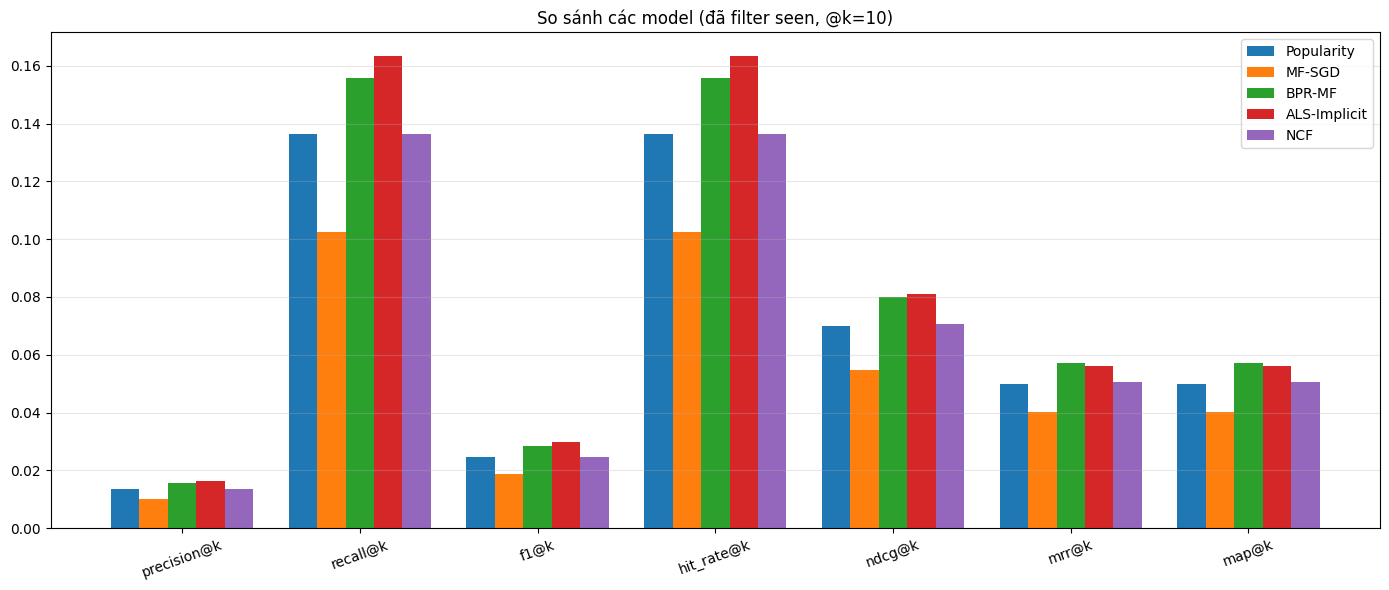

[Saved] ..\data\artifacts\cf\20261019_185104_1000000\20261019_185104_1000000_comparison_FINAL.csv


In [ ]:
import pandas as pd

results = []
for name, res in [
    ("Popularity", pop_test),
    ("MF-SGD",     mf_test),
    ("BPR-MF",     bpr_test),
    ("ALS-Implicit", als_test),
    ("NCF",         ncf_test)
]:
    results.append({"Model": name, **{k:v for k,v in res.items() if k not in ("k","n_users")}})

df_compare = pd.DataFrame(results).set_index("Model")
df_compare = df_compare[["precision@k","recall@k","f1@k","hit_rate@k","ndcg@k","mrr@k","map@k"]]
df_compare = df_compare.round(4)

print("\n" + "="*90)
print("BẢNG SO SÁNH — TẤT CẢ ĐÃ FILTER SEEN ITEMS (@k=10)")
print("="*90)
display(df_compare)

# Vẽ bar chart
import matplotlib.pyplot as plt
metrics = ["precision@k","recall@k","f1@k","hit_rate@k","ndcg@k","mrr@k","map@k"]
x = np.arange(len(metrics)); w = 0.8/len(df_compare)
fig, ax = plt.subplots(figsize=(14, 6))
for i, model in enumerate(df_compare.index):
    ax.bar(x + (i - len(df_compare)/2 + 0.5)*w, df_compare.loc[model, metrics], w, label=model)
ax.set_xticks(x); ax.set_xticklabels(metrics, rotation=20)
ax.set_title("So sánh các model (đã filter seen, @k=10)")
ax.legend(); ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
model_comparison_path = get_timestamped_path(dir_path_with_timestamp, "comparison_FINAL.png")
plt.savefig(model_comparison_path, dpi=150)
plt.show()

# Lưu CSV
compare_csv_path = get_timestamped_path(dir_path_with_timestamp, "comparison_FINAL.csv")
df_compare.to_csv(compare_csv_path)
print(f"[Saved] {compare_csv_path}")

In [ ]:
def tune_bpr(grid, train_df, val_df, num_movies):
    results = []
    for cfg in grid:
        print(f"\n[Grid Search] Training BPR-MF with config: {cfg}")
        m = BPR_MF(num_users, num_movies, dim=cfg["dim"])
        
        tune_bpr_path = get_timestamped_path(dir_path_with_timestamp, f"tune_bpr_dim{cfg['dim']}_lr{cfg['lr']}.pt")
        m = train_bpr(m, train_df, num_movies, val_df,
                      epochs=cfg["epochs"], lr=cfg["lr"], batch_size=4096,
                      patience=2, ckpt_path=tune_bpr_path, seed=42)
        val_m = evaluate_recommender(m, val_df, train_df, k=10, verbose=False)
        results.append({**cfg, **{f"val_{k}":v for k,v in val_m.items() if k not in ("k","n_users")}})
        print(f"  → {cfg} | Val NDCG@10={val_m['ndcg@k']:.4f}")
        
    return pd.DataFrame(results).sort_values("val_ndcg@k", ascending=False)

# Ví dụ grid nhỏ — chạy hết khoảng 15–25 phút trên CPU
grid = [
    {"dim":32, "lr":1e-3, "epochs":10},
    {"dim":64, "lr":1e-3, "epochs":10},
    {"dim":64, "lr":2e-3, "epochs":10},
    {"dim":128,"lr":1e-3, "epochs":10},
]
# df_tune = tune_bpr(grid, train_df, val_df, num_movies)
# display(df_tune)